# Generating brain growth charts using HBCD data

## Introduction
The size of structural volumes is potentially meaningful with respect to brain function. Therefore, one fundamental question underlying ABCD and HBCD studies are the developmental trajectories of brain regions. Providing brain charts is an incredibly important tool for tracking developmental growth and providing normative models for biomarker discovery (Bethlehem et. al., Nature, 2022 ). One key gap in brain charts is the lack of a consistent pipeline for processing all the data -- trajectories may be contaminated by batch effects from differences in pipeline processing. In addition, some ages in current brain charts may be limited due to small sample sizes. BIBSnet provides volumetric outputs for the HBCD dataset. Here, we will load BIBSnet data and measure the trajectory of volumetric data across development filling the gap in infant development.



## Step 1: Install required Python modules then import
Some python modules may be needed for the HDCC workshop itself. If these are not available, run the below code chunk. `scipy` is good for modelling and curve fitting. `seaborn` is good for plotting pretty graphics. `nibabel` is useful for saving output for brain-based visualizations. Feel free to include more packages by supplying additional `!pip3 install <packagename>` lines where `<packagename>` is the name of the python package you want to install.


In [ ]:
!pip3 install scipy
!pip3 install seaborn
!pip3 install nibabel

Defaulting to user installation because normal site-packages is not writeable
Defaulting to user installation because normal site-packages is not writeable
Defaulting to user installation because normal site-packages is not writeable
     |████████████████████████████████| 3.3 MB 5.5 MB/s eta 0:00:01


In [ ]:
#import modules needed for plotting and manipulating data
import pandas as pd #good for manipulating data frames
import numpy as np #good for mathematical calculations and computing
import matplotlib.pyplot as plt #good for plotting "MATLAB" like graphics

Matplotlib is building the font cache; this may take a moment.


## Step 2: Load Tabulated HBCD BIBSNet Data

### Choosing your tabulated input data

You can choose what tabulated data file you would like to load by editing code block 3 in the ipython notebook, reprinted below. This can be done to select not just imaging measures, but clinical or cognitive measures as well. The code below will take the `img_bibsnet_space-T1w_desc-aseg_volumes.tsv` and load it into a `DataFrame` in the jupyter notebook.

In [ ]:
df = pd.read_csv('/shared/hackathon/hbcd/v2.0/hbcd/rawdata/phenotype/img_bibsnet_space-T1w_desc-aseg_volumes.tsv', sep='\t')
df.head

<bound method NDFrame.head of       participant_id session_id  \
0     sub-5825700105    ses-V04   
1     sub-6913742413    ses-V04   
2     sub-9886044379    ses-V04   
3     sub-9761650740    ses-V04   
4     sub-6718462907    ses-V04   
...              ...        ...   
1572  sub-3700212247    ses-V04   
1573  sub-1629866253    ses-V04   
1574  sub-8199772766    ses-V04   
1575  sub-3545593846    ses-V04   
1576  sub-3231719688    ses-V04   

      img_bibsnet_space-T1w_desc-aseg_volumes_candidate_age  \
0                                                 0.868       
1                                                 0.914       
2                                                 0.980       
3                                                 0.868       
4                                                 0.876       
...                                                 ...       
1572                                              0.887       
1573                                         

## Step 3: Visualize Brain Growth with Scatter Plots

### Step 3a: Plot ROI volume (here we will use Left Cerebral Cortex as an example) vs. Candidate Age (in years)

Visualizing your data is key to answering your study questions and communicating those answers. Here, we can make simple brain growth scatter plots using code block 4. The code for making this plot is reprinted below. The figure size can be adjusted by changing `figsize`. You can select another measure for the X axis by changing `img_bibsnet_space-T1w_desc-aseg_volumes_candidate_age` to another variable in the `DataFrame`. Similarly, you can select another measure for the Y axis by changing `img_bibsnet_space-T1w_desc-aseg_volumes_Left-Cerebral-Cortex`. `alpha` controls how transparent the figure will be. `plt.xlabel`, `plt.ylabel`, `plt.title` all edit the labels for the X axis, Y axis, and title. `plt.grid(True)` maintains grid lines, while `plt.show()` displays the figure. More complex figures are available in the python notebook that one can use for flashier displays!

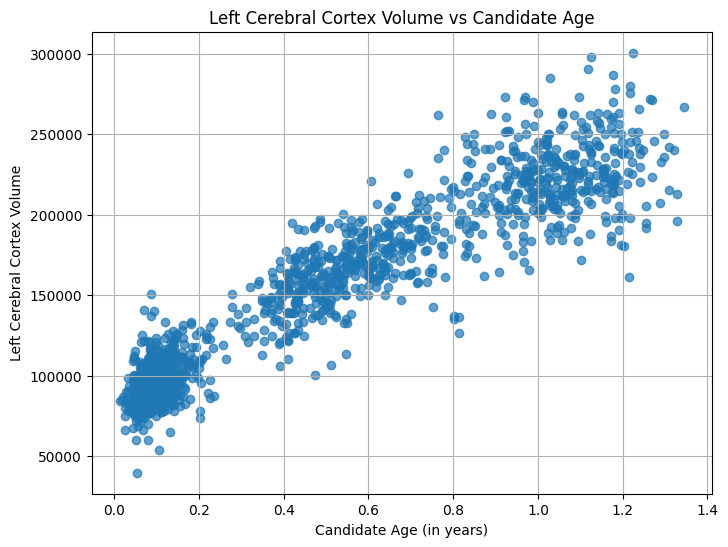

In [ ]:
# Plot
plt.figure(figsize=(8,6))
plt.scatter(
    df['img_bibsnet_space-T1w_desc-aseg_volumes_candidate_age'],
    df['img_bibsnet_space-T1w_desc-aseg_volumes_Left-Cerebral-Cortex'],
    alpha=0.7
)
plt.xlabel('Candidate Age (in years)')
plt.ylabel('Left Cerebral Cortex Volume')
plt.title('Left Cerebral Cortex Volume vs Candidate Age')
plt.grid(True)
plt.show()

### Step 3b: Plot ROI volume (again using Left Cerebral Cortex as an example) vs. Candidate Age (in years) for each individual participant across study visits (i.e. sessions)

In [ ]:
# Group by session_ID (e.g. ses-V02 corresponds to study Visit 2) and identify number of unique participants per visit
df.groupby('session_id')['participant_id'].nunique()

session_id
ses-V02    792
ses-V03    410
ses-V04    375
Name: participant_id, dtype: int64

In [ ]:
# Count the number of unique sessions per participant
session_counts = df.groupby('participant_id')['session_id'].nunique().reset_index()
session_counts = session_counts.rename(columns={'session_id': 'n_sessions'})

# Display the summary
print(session_counts)

      participant_id  n_sessions
0     sub-1011897476           1
1     sub-1017033270           2
2     sub-1018704349           1
3     sub-1021546683           1
4     sub-1023375424           1
...              ...         ...
1165  sub-9989776259           2
1166  sub-9990821187           1
1167  sub-9992030024           1
1168  sub-9997323663           1
1169  sub-9999560662           1

[1170 rows x 2 columns]


In [ ]:
# Count how many subjects have X sessions
distribution = session_counts['n_sessions'].value_counts().sort_index()
print(distribution)

n_sessions
1    826
2    281
3     63
Name: count, dtype: int64


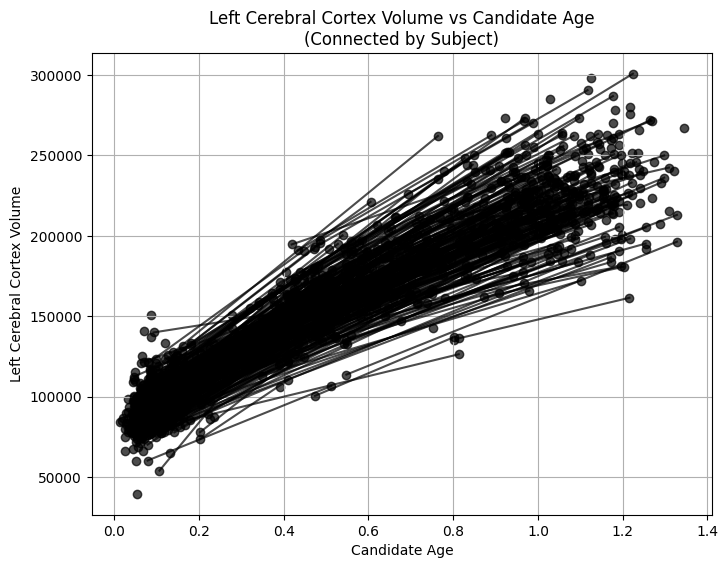

In [ ]:
plt.figure(figsize=(8,6))

for pid, group in df.groupby('participant_id'):
    group_sorted = group.sort_values('img_bibsnet_space-T1w_desc-aseg_volumes_candidate_age')
    
    if len(group_sorted) > 1:
        plt.plot(
            group_sorted['img_bibsnet_space-T1w_desc-aseg_volumes_candidate_age'],
            group_sorted['img_bibsnet_space-T1w_desc-aseg_volumes_Left-Cerebral-Cortex'],
            marker='o', 
            alpha=0.7,
            linestyle='-', 
            color='black'
        )
    else:
        plt.scatter(
            group_sorted['img_bibsnet_space-T1w_desc-aseg_volumes_candidate_age'],
            group_sorted['img_bibsnet_space-T1w_desc-aseg_volumes_Left-Cerebral-Cortex'],
            alpha=0.7,
            color='black'
        )

plt.xlabel('Candidate Age')
plt.ylabel('Left Cerebral Cortex Volume')
plt.title('Left Cerebral Cortex Volume vs Candidate Age\n(Connected by Subject)')
plt.grid(True)
plt.show()

## Step 4: Fit data with growth curves using different models and plot

### Step 4a: Quadratic Polynomial Fit

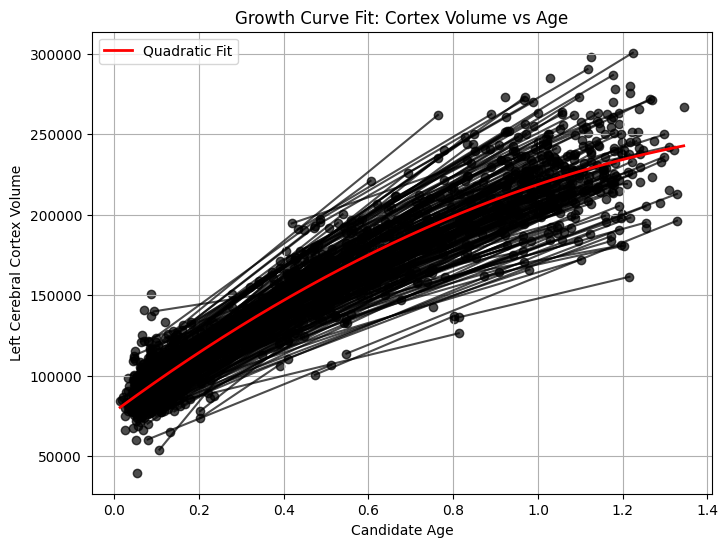

In [ ]:
import numpy as np
from numpy.polynomial.polynomial import Polynomial
import matplotlib.pyplot as plt

# Flatten the data to one array (ignoring repeated participants here)
x = df['img_bibsnet_space-T1w_desc-aseg_volumes_candidate_age'].values
y = df['img_bibsnet_space-T1w_desc-aseg_volumes_Left-Cerebral-Cortex'].values

# Fit a degree-2 polynomial (quadratic)
coefs = Polynomial.fit(x, y, deg=2).convert().coef

# Generate a smooth curve for plotting
x_curve = np.linspace(x.min(), x.max(), 200)
y_curve = coefs[0] + coefs[1]*x_curve + coefs[2]*x_curve**2

plt.figure(figsize=(8,6))
# Plot individual data as described previously (in black)
for pid, group in df.groupby('participant_id'):
    group_sorted = group.sort_values('img_bibsnet_space-T1w_desc-aseg_volumes_candidate_age')
    if len(group_sorted) > 1:
        plt.plot(group_sorted['img_bibsnet_space-T1w_desc-aseg_volumes_candidate_age'],
                 group_sorted['img_bibsnet_space-T1w_desc-aseg_volumes_Left-Cerebral-Cortex'],
                 marker='o', alpha=0.7, linestyle='-', color='black')
    else:
        plt.scatter(group_sorted['img_bibsnet_space-T1w_desc-aseg_volumes_candidate_age'],
                    group_sorted['img_bibsnet_space-T1w_desc-aseg_volumes_Left-Cerebral-Cortex'],
                    alpha=0.7, color='black')

# Plot the fitted curve
plt.plot(x_curve, y_curve, color='red', linewidth=2, label='Quadratic Fit')
plt.xlabel('Candidate Age')
plt.ylabel('Left Cerebral Cortex Volume')
plt.title('Growth Curve Fit: Cortex Volume vs Age')
plt.grid(True)
plt.legend()
plt.show()

### Step 4b: Sigmoid (Logistic) Fit

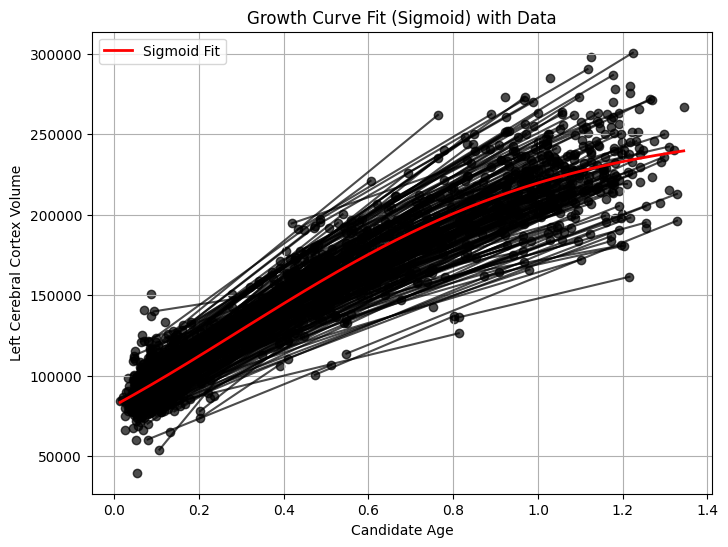

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

# Prepare data arrays from your DataFrame
x = df['img_bibsnet_space-T1w_desc-aseg_volumes_candidate_age'].values
y = df['img_bibsnet_space-T1w_desc-aseg_volumes_Left-Cerebral-Cortex'].values

# Define the sigmoid (logistic) function
def sigmoid(x, L, x0, k, b):
    return L / (1 + np.exp(-k*(x-x0))) + b

# Fit the curve (initial guess: [max(y), median(x), 1, min(y)])
popt, _ = curve_fit(sigmoid, x, y, p0=[max(y), np.median(x), 1, min(y)])

# Create smooth x and y values for the fit curve
x_curve = np.linspace(x.min(), x.max(), 200)
y_curve = sigmoid(x_curve, *popt)

plt.figure(figsize=(8, 6))

# Plot the underlying data points, connected by subject as before
for pid, group in df.groupby('participant_id'):
    group_sorted = group.sort_values('img_bibsnet_space-T1w_desc-aseg_volumes_candidate_age')
    if len(group_sorted) > 1:
        plt.plot(group_sorted['img_bibsnet_space-T1w_desc-aseg_volumes_candidate_age'],
                 group_sorted['img_bibsnet_space-T1w_desc-aseg_volumes_Left-Cerebral-Cortex'],
                 marker='o', alpha=0.7, linestyle='-', color='black')
    else:
        plt.scatter(group_sorted['img_bibsnet_space-T1w_desc-aseg_volumes_candidate_age'],
                    group_sorted['img_bibsnet_space-T1w_desc-aseg_volumes_Left-Cerebral-Cortex'],
                    alpha=0.7, color='black')

# Add the nonlinear fit curve
plt.plot(x_curve, y_curve, color='red', linewidth=2, label='Sigmoid Fit')

plt.xlabel('Candidate Age')
plt.ylabel('Left Cerebral Cortex Volume')
plt.title('Growth Curve Fit (Sigmoid) with Data')
plt.grid(True)
plt.legend()
plt.show()

### Step 4c: Plot data color-coded by visit

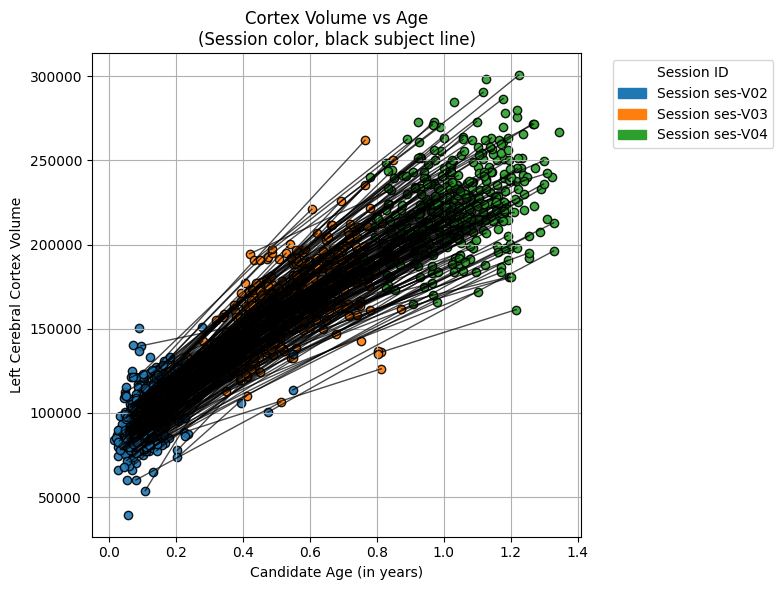

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

# Choose a qualitative color map (extend if you have >10 sessions)
color_palette = plt.cm.tab10.colors
session_ids = sorted(df['session_id'].unique())
session_colors = dict(zip(session_ids, color_palette[:len(session_ids)]))

plt.figure(figsize=(8,6))

# Plot points by session color and connect sessions for each subject
for pid, group in df.groupby('participant_id'):
    group_sorted = group.sort_values('img_bibsnet_space-T1w_desc-aseg_volumes_candidate_age')
    
    # Plot colored points for each session
    for sid in session_ids:
        session_group = group_sorted[group_sorted['session_id'] == sid]
        if not session_group.empty:
            plt.scatter(session_group['img_bibsnet_space-T1w_desc-aseg_volumes_candidate_age'],
                        session_group['img_bibsnet_space-T1w_desc-aseg_volumes_Left-Cerebral-Cortex'],
                        color=session_colors[sid], alpha=0.9, edgecolor='black', label=None)
    # Add black connecting line for subjects with multiple sessions
    if len(group_sorted) > 1:
        plt.plot(group_sorted['img_bibsnet_space-T1w_desc-aseg_volumes_candidate_age'],
                 group_sorted['img_bibsnet_space-T1w_desc-aseg_volumes_Left-Cerebral-Cortex'],
                 color='black', alpha=0.7, linewidth=1)

# Custom legend for session colors
handles = [mpatches.Patch(color=session_colors[sid], label=f'Session {sid}') for sid in session_ids]
plt.legend(handles=handles, title='Session ID', bbox_to_anchor=(1.05, 1), loc='upper left')

plt.xlabel('Candidate Age (in years)')
plt.ylabel('Left Cerebral Cortex Volume')
plt.title('Cortex Volume vs Age\n(Session color, black subject line)')
plt.grid(True)
plt.tight_layout()
plt.show()

### Step 4d: Plot data color-coded by visit with sigmoid fit

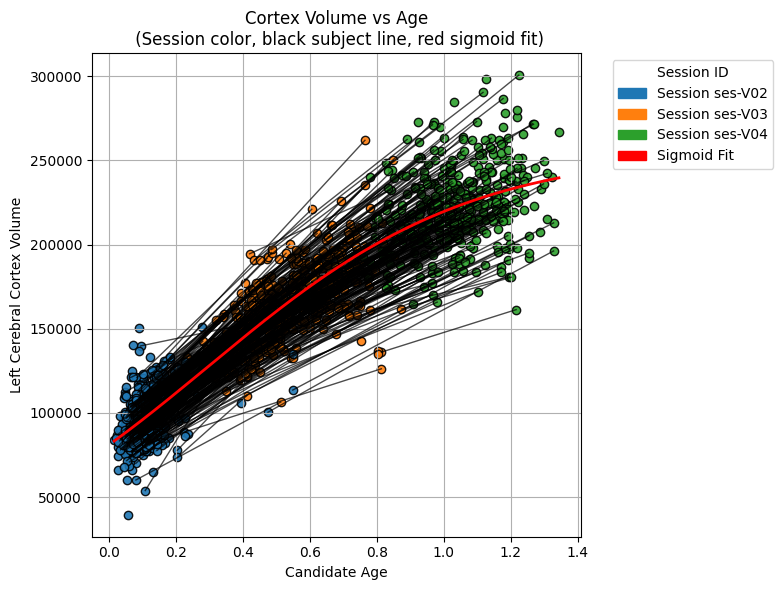

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from scipy.optimize import curve_fit

# Prepare data arrays from your DataFrame
x = df['img_bibsnet_space-T1w_desc-aseg_volumes_candidate_age'].values
y = df['img_bibsnet_space-T1w_desc-aseg_volumes_Left-Cerebral-Cortex'].values

# Define the sigmoid (logistic) function
def sigmoid(x, L, x0, k, b):
    return L / (1 + np.exp(-k*(x-x0))) + b

# Fit the curve (initial guess: [max(y), median(x), 1, min(y)])
popt, _ = curve_fit(sigmoid, x, y, p0=[max(y), np.median(x), 1, min(y)])

# Create smooth x and y values for the fit curve
x_curve = np.linspace(x.min(), x.max(), 200)
y_curve = sigmoid(x_curve, *popt)

# Choose a qualitative color map
color_palette = plt.cm.tab10.colors
session_ids = sorted(df['session_id'].unique())
session_colors = dict(zip(session_ids, color_palette[:len(session_ids)]))

plt.figure(figsize=(8,6))

# Plot points by session color and connect sessions for each subject
for pid, group in df.groupby('participant_id'):
    group_sorted = group.sort_values('img_bibsnet_space-T1w_desc-aseg_volumes_candidate_age')
    # Plot colored points for each session
    for sid in session_ids:
        session_group = group_sorted[group_sorted['session_id'] == sid]
        if not session_group.empty:
            plt.scatter(session_group['img_bibsnet_space-T1w_desc-aseg_volumes_candidate_age'],
                        session_group['img_bibsnet_space-T1w_desc-aseg_volumes_Left-Cerebral-Cortex'],
                        color=session_colors[sid], alpha=0.9, edgecolor='black', label=None)
    # Add black connecting line for subjects with multiple sessions
    if len(group_sorted) > 1:
        plt.plot(group_sorted['img_bibsnet_space-T1w_desc-aseg_volumes_candidate_age'],
                 group_sorted['img_bibsnet_space-T1w_desc-aseg_volumes_Left-Cerebral-Cortex'],
                 color='black', alpha=0.7, linewidth=1)

# Add the nonlinear fit curve (in red)
plt.plot(x_curve, y_curve, color='red', linewidth=2, label='Sigmoid (logistic) Fit')

# Custom legend for session colors
handles = [mpatches.Patch(color=session_colors[sid], label=f'Session {sid}') for sid in session_ids]
handles.append(mpatches.Patch(color='red', label='Sigmoid Fit'))
plt.legend(handles=handles, title='Session ID', bbox_to_anchor=(1.05, 1), loc='upper left')

plt.xlabel('Candidate Age')
plt.ylabel('Left Cerebral Cortex Volume')
plt.title('Cortex Volume vs Age\n (Session color, black subject line, red sigmoid fit)')
plt.grid(True)
plt.tight_layout()
plt.show()

### Step 4e: Plot data color-coded by visit with polynomial fit and %95 confidence intervals

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

# Prepare data
x = df['img_bibsnet_space-T1w_desc-aseg_volumes_candidate_age'].values
y = df['img_bibsnet_space-T1w_desc-aseg_volumes_Left-Cerebral-Cortex'].values

# Fit a degree-2 polynomial
coefs = np.polyfit(x, y, 2)  # coefs[0]*x^2 + coefs[1]*x + coefs[2]

# Fit predictions on a smooth grid
x_curve = np.linspace(x.min(), x.max(), 200)
y_poly = np.polyval(coefs, x_curve)

In [ ]:
# Design matrix for original data (X) and curve points (X_pred)
X = np.vstack([x**2, x, np.ones_like(x)]).T
X_pred = np.vstack([x_curve**2, x_curve, np.ones_like(x_curve)]).T

# Estimate residual variance
y_fit = np.polyval(coefs, x)
residuals = y - y_fit
dof = len(x) - 3  # Three parameters for quadratic
residual_var = (residuals**2).sum() / dof

# Covariance matrix of coefficients
XtX_inv = np.linalg.inv(X.T @ X)
# Standard errors prediction intervals at each point
y_var_pred = np.array([residual_var * (np.dot(X_pred[i], XtX_inv @ X_pred[i])) for i in range(len(x_curve))])
y_std_pred = np.sqrt(y_var_pred)

# 95% CI
ci_upper = y_poly + 1.96 * y_std_pred
ci_lower = y_poly - 1.96 * y_std_pred

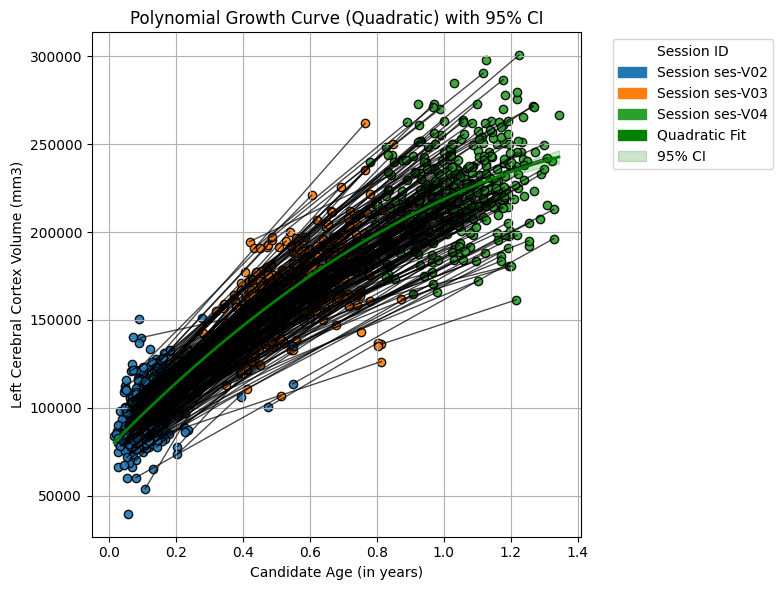

In [ ]:
# Color mapping for sessions
color_palette = plt.cm.tab10.colors
session_ids = sorted(df['session_id'].unique())
session_colors = dict(zip(session_ids, color_palette[:len(session_ids)]))

plt.figure(figsize=(8,6))

# Plot points by session color and connect lines by subject
for pid, group in df.groupby('participant_id'):
    group_sorted = group.sort_values('img_bibsnet_space-T1w_desc-aseg_volumes_candidate_age')
    for sid in session_ids:
        session_group = group_sorted[group_sorted['session_id'] == sid]
        if not session_group.empty:
            plt.scatter(session_group['img_bibsnet_space-T1w_desc-aseg_volumes_candidate_age'],
                        session_group['img_bibsnet_space-T1w_desc-aseg_volumes_Left-Cerebral-Cortex'],
                        color=session_colors[sid], alpha=0.9, edgecolor='black', label=None)
    if len(group_sorted) > 1:
        plt.plot(group_sorted['img_bibsnet_space-T1w_desc-aseg_volumes_candidate_age'],
                 group_sorted['img_bibsnet_space-T1w_desc-aseg_volumes_Left-Cerebral-Cortex'],
                 color='black', alpha=0.7, linewidth=1)

# Plot polynomial fit with CI
plt.plot(x_curve, y_poly, color='green', linewidth=2, label='Quadratic Fit')
plt.fill_between(x_curve, ci_lower, ci_upper, color='green', alpha=0.2, label='95% CI')

# Custom legend
handles = [mpatches.Patch(color=session_colors[sid], label=f'Session {sid}') for sid in session_ids]
handles += [
    mpatches.Patch(color='green', label='Quadratic Fit'),
    mpatches.Patch(color='green', alpha=0.2, label='95% CI')
]
plt.legend(handles=handles, title='Session ID', bbox_to_anchor=(1.05, 1), loc='upper left')

plt.xlabel('Candidate Age (in years)')
plt.ylabel('Left Cerebral Cortex Volume (mm3)')
plt.title('Polynomial Growth Curve (Quadratic) with 95% CI')
plt.grid(True)
plt.tight_layout()
plt.show()

### Step 4f: Loop through all brain volume measures and produce 4e brain charts for all measures

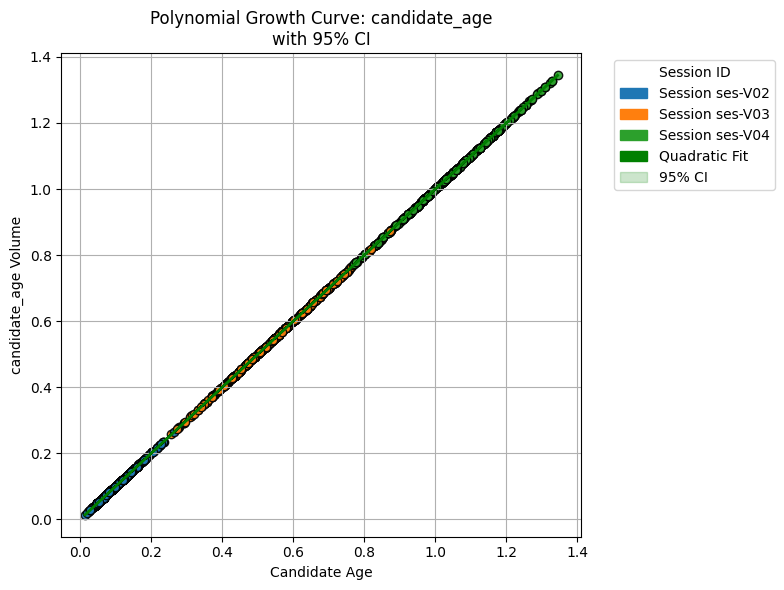

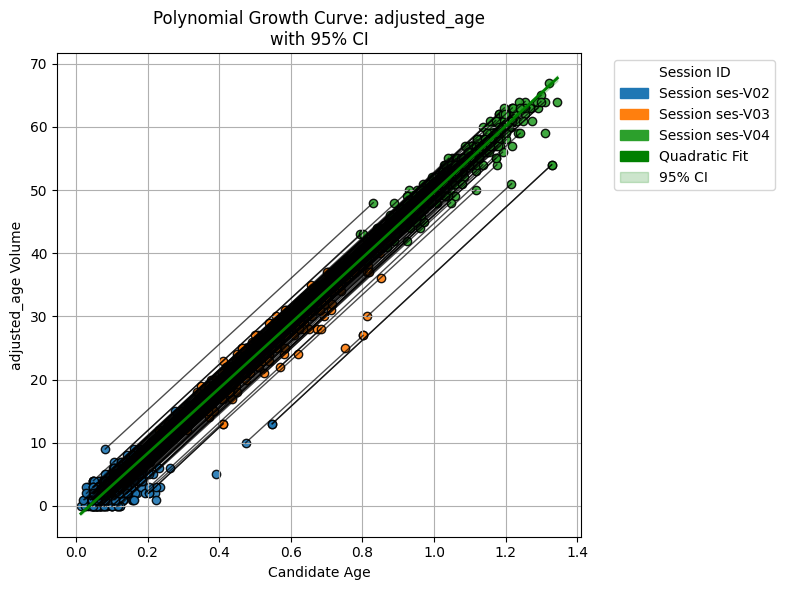

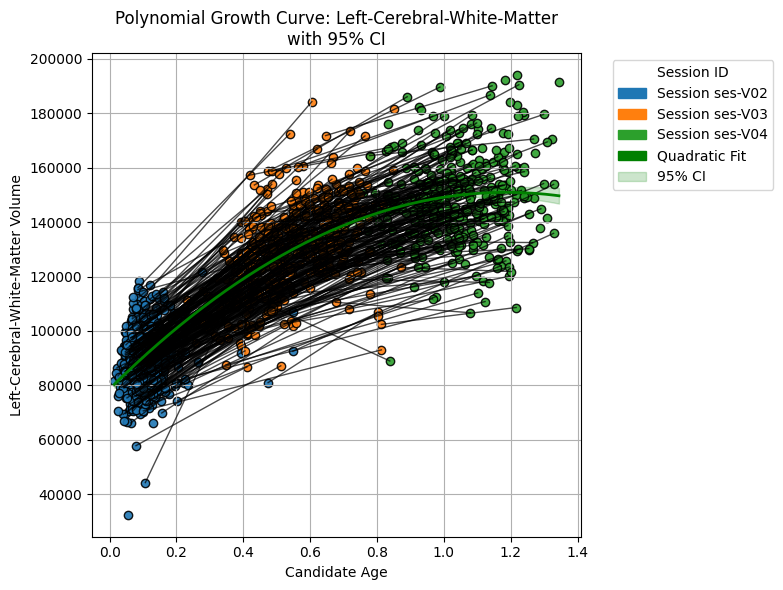

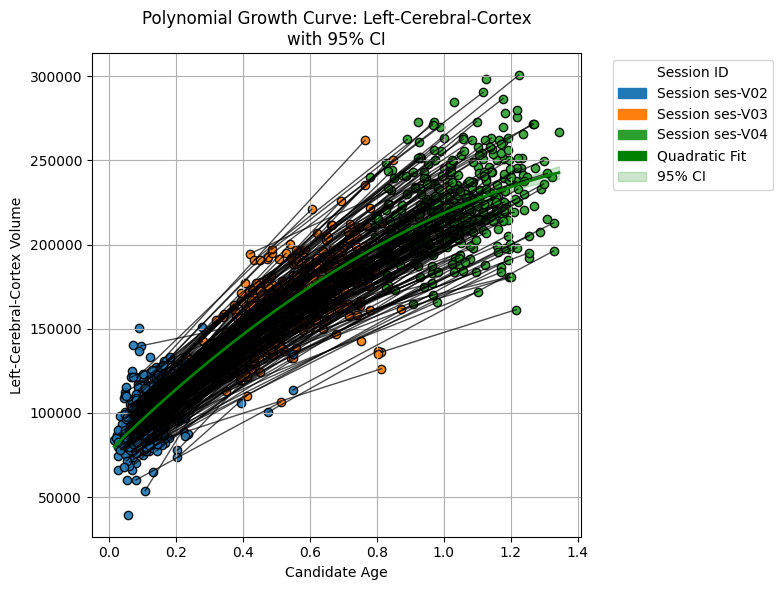

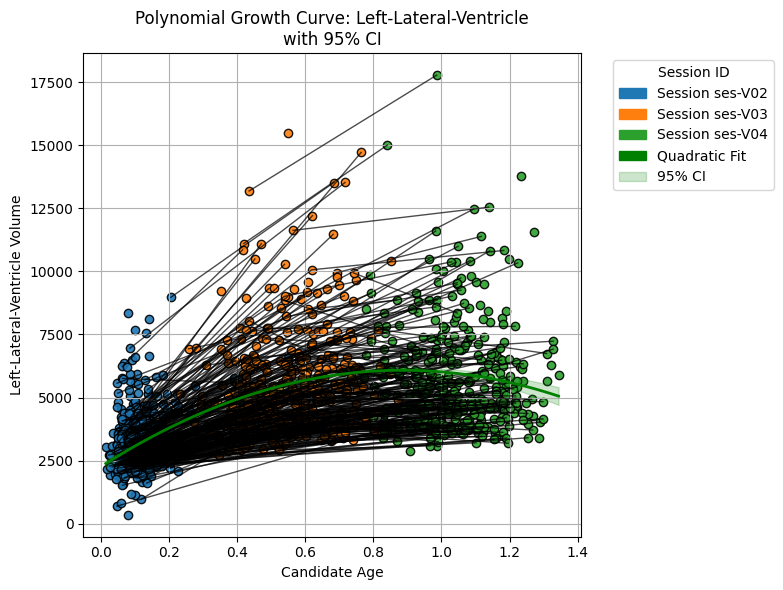

...

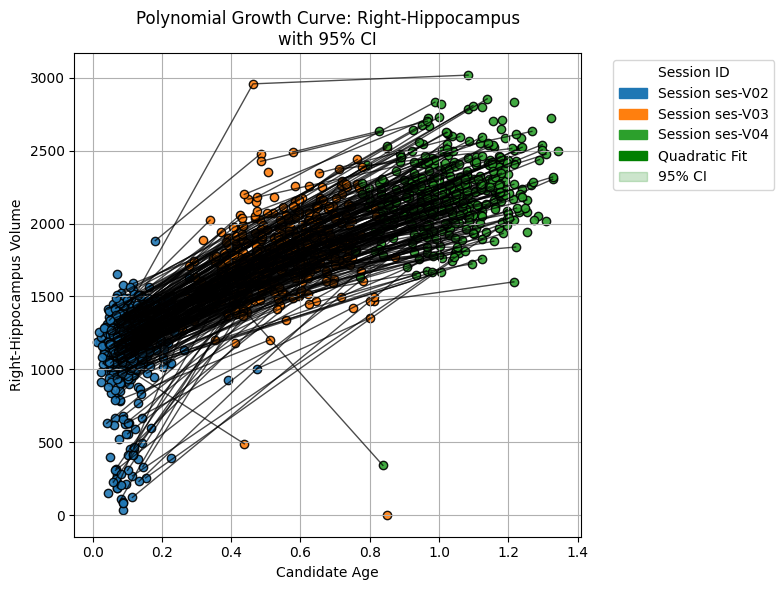

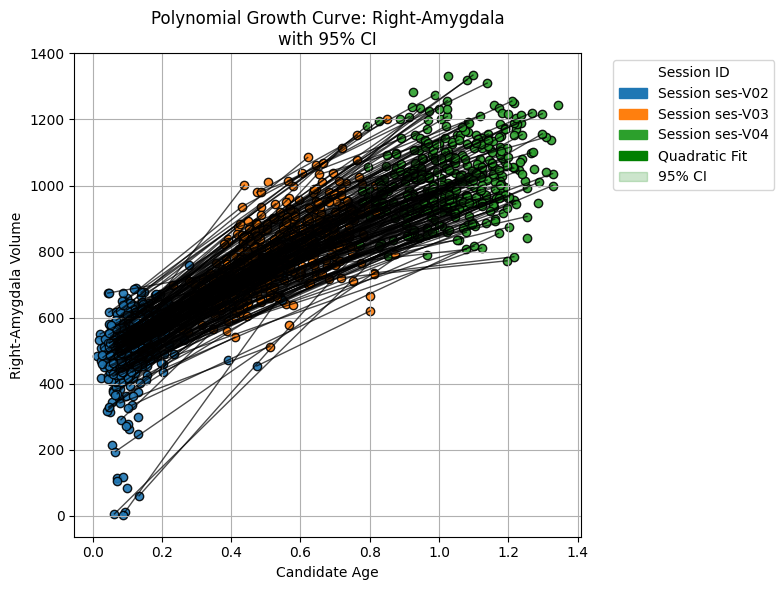

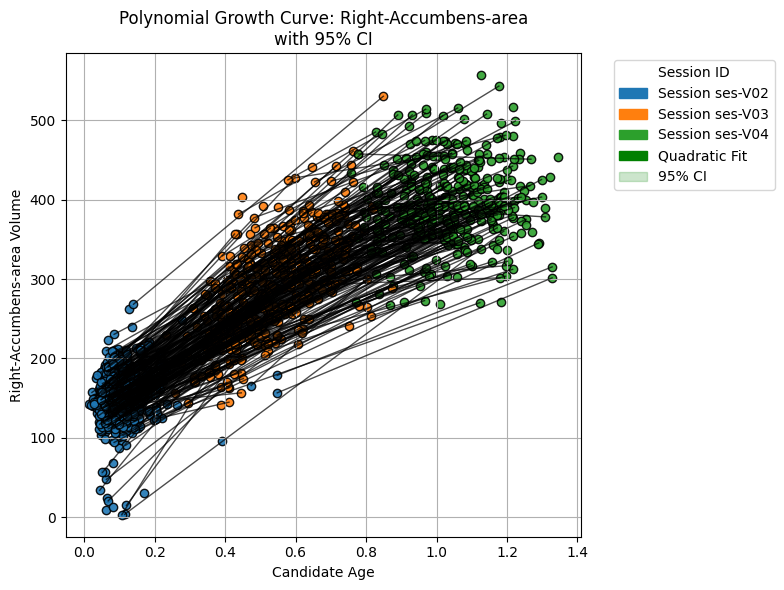

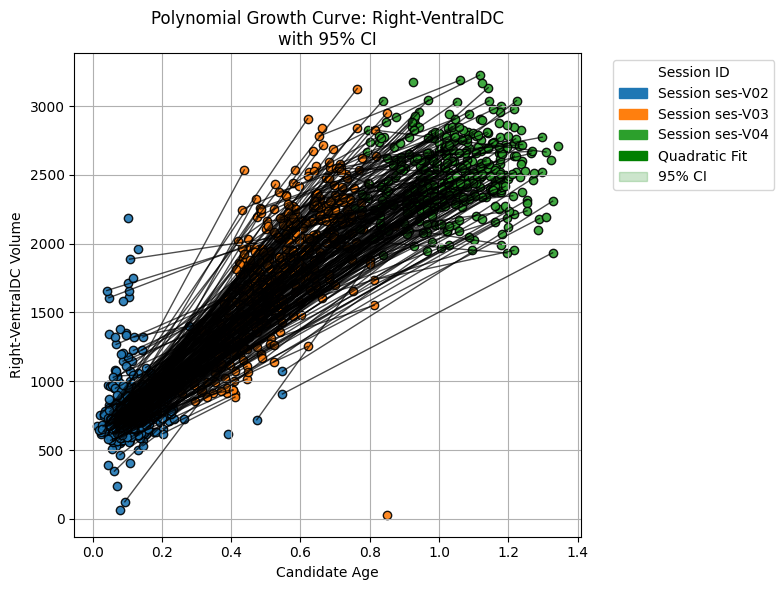

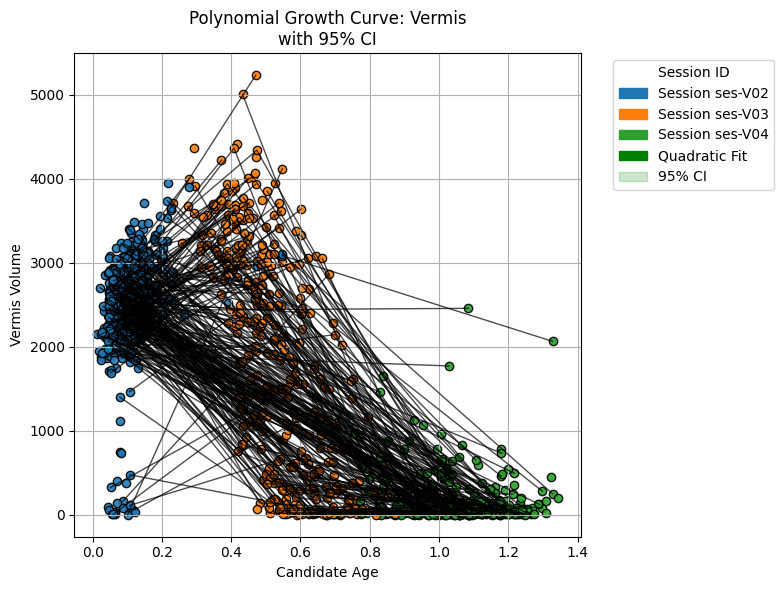

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

def plot_all_regions(df, age_col, participant_col, session_col, prefix="img_bibsnet_space-T1w_desc-aseg_volumes_"):
    # Find region columns (skip first 3 columns, adjust as needed)
    region_cols = [col for col in df.columns if col.startswith(prefix)]
    
    # Prepare session colors (matplotlib 'tab10' can color up to 10 sessions)
    color_palette = plt.cm.tab10.colors
    session_ids = sorted(df[session_col].unique())
    session_colors = dict(zip(session_ids, color_palette[:len(session_ids)]))
    
    for region_col in region_cols:
        # Clean region name for plot purposes
        region_name = region_col.replace(prefix, '')
        
        x = df[age_col].values
        y = df[region_col].values
        
        # Polynomial fit & CI
        coefs = np.polyfit(x, y, 2)
        x_curve = np.linspace(x.min(), x.max(), 200)
        y_poly = np.polyval(coefs, x_curve)
        # Design matrices
        X = np.vstack([x**2, x, np.ones_like(x)]).T
        X_pred = np.vstack([x_curve**2, x_curve, np.ones_like(x_curve)]).T
        y_fit = np.polyval(coefs, x)
        residuals = y - y_fit
        dof = len(x) - 3
        residual_var = (residuals**2).sum() / dof
        XtX_inv = np.linalg.inv(X.T @ X)
        y_var_pred = np.array([residual_var * (np.dot(X_pred[i], XtX_inv @ X_pred[i])) for i in range(len(x_curve))])
        y_std_pred = np.sqrt(y_var_pred)
        ci_upper = y_poly + 1.96 * y_std_pred
        ci_lower = y_poly - 1.96 * y_std_pred
        
        # Start plotting
        plt.figure(figsize=(8,6))
        # Colored points and black subject lines
        for pid, group in df.groupby(participant_col):
            group_sorted = group.sort_values(age_col)
            for sid in session_ids:
                session_group = group_sorted[group_sorted[session_col] == sid]
                if not session_group.empty:
                    plt.scatter(session_group[age_col], session_group[region_col],
                                color=session_colors[sid], alpha=0.9, edgecolor='black', label=None)
            if len(group_sorted) > 1:
                plt.plot(group_sorted[age_col], group_sorted[region_col],
                         color='black', alpha=0.7, linewidth=1)
        # Poly fit curve and CI
        plt.plot(x_curve, y_poly, color='green', linewidth=2, label='Quadratic Fit')
        plt.fill_between(x_curve, ci_lower, ci_upper, color='green', alpha=0.2, label='95% CI')
        # Legend
        handles = [mpatches.Patch(color=session_colors[sid], label=f'Session {sid}') for sid in session_ids]
        handles += [
            mpatches.Patch(color='green', label='Quadratic Fit'),
            mpatches.Patch(color='green', alpha=0.2, label='95% CI')
        ]
        plt.legend(handles=handles, title='Session ID', bbox_to_anchor=(1.05, 1), loc='upper left')
        plt.xlabel('Candidate Age')
        plt.ylabel(f'{region_name} Volume')
        plt.title(f'Polynomial Growth Curve: {region_name}\nwith 95% CI')
        plt.grid(True)
        plt.tight_layout()
        # Optionally, save the plot:
        # plt.savefig(f'growth_curve_{region_name}.png')
        plt.show()

# Usage
plot_all_regions(
    df,
    age_col='img_bibsnet_space-T1w_desc-aseg_volumes_candidate_age',
    participant_col='participant_id',
    session_col='session_id',
    prefix='img_bibsnet_space-T1w_desc-aseg_volumes_'
)

### plot all charts as Left/Right pairs 

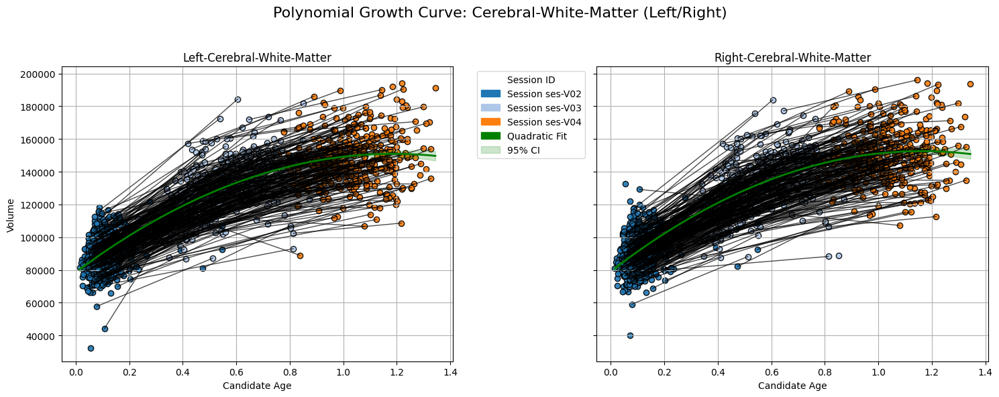

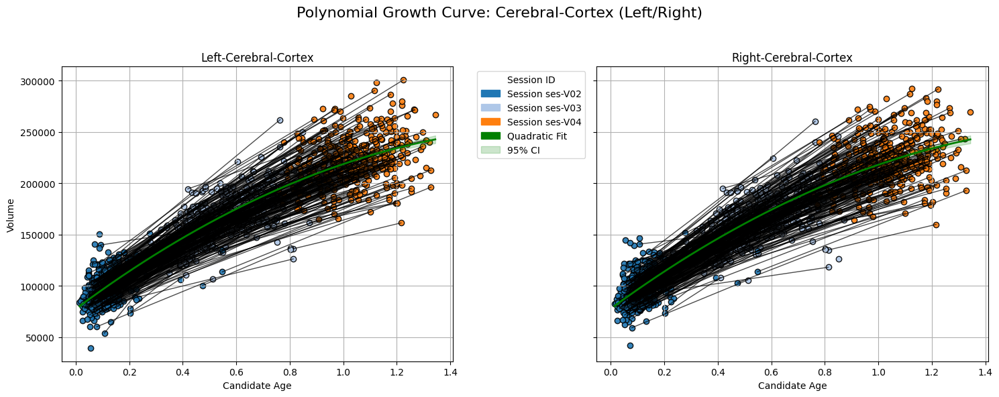

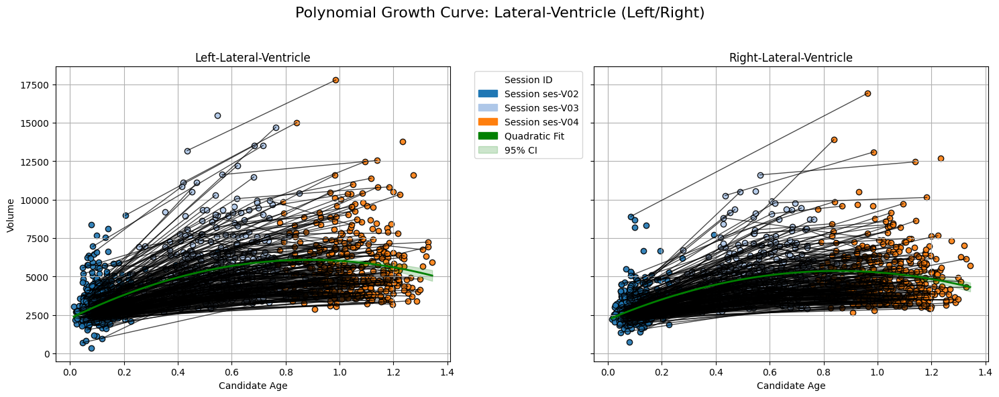

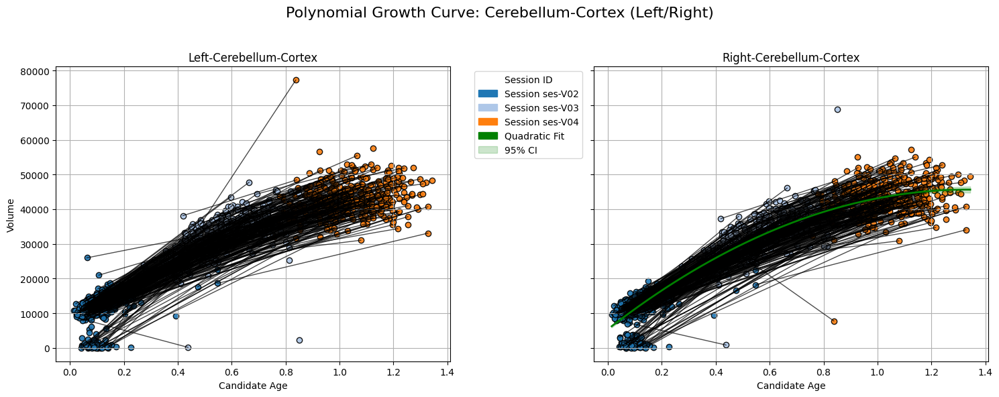

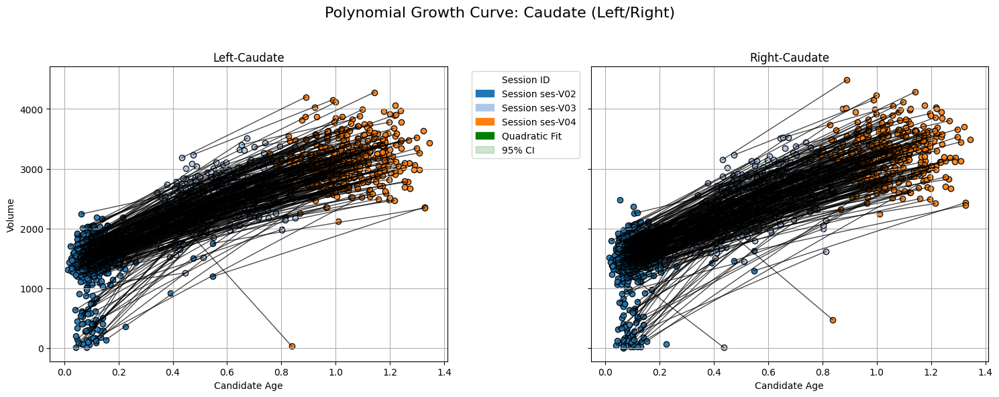

...

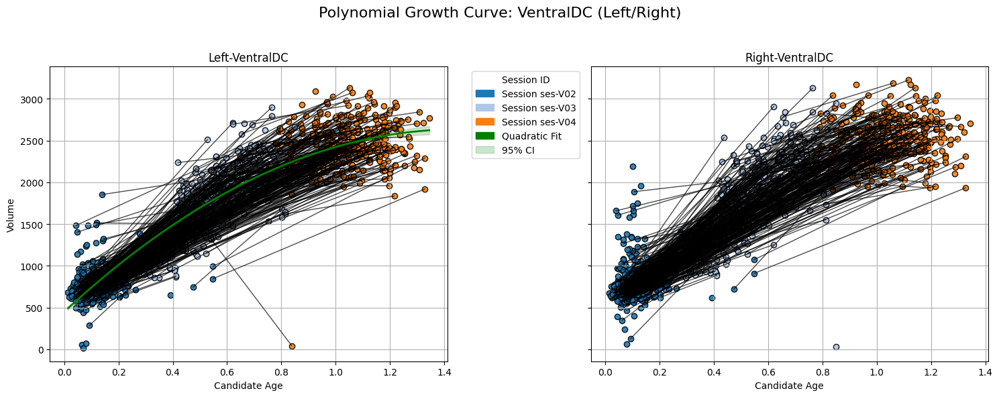

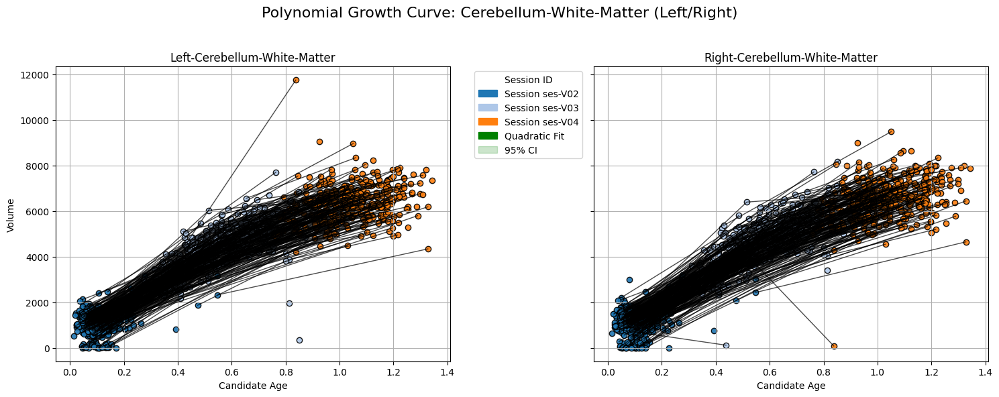

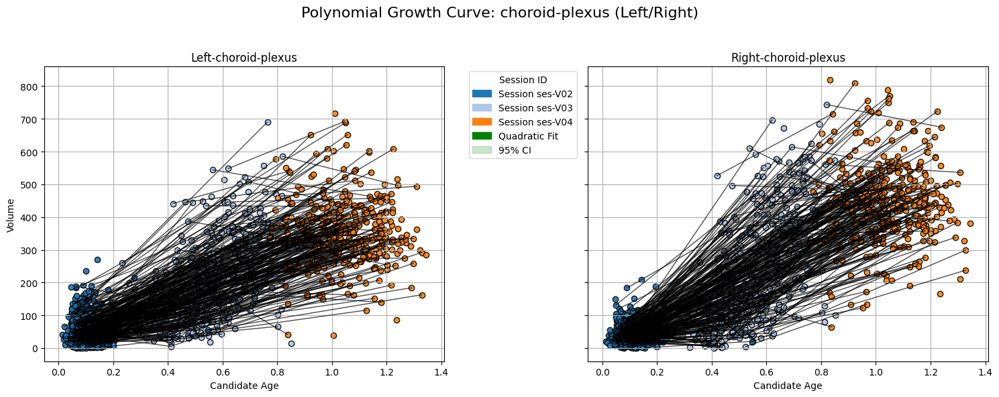

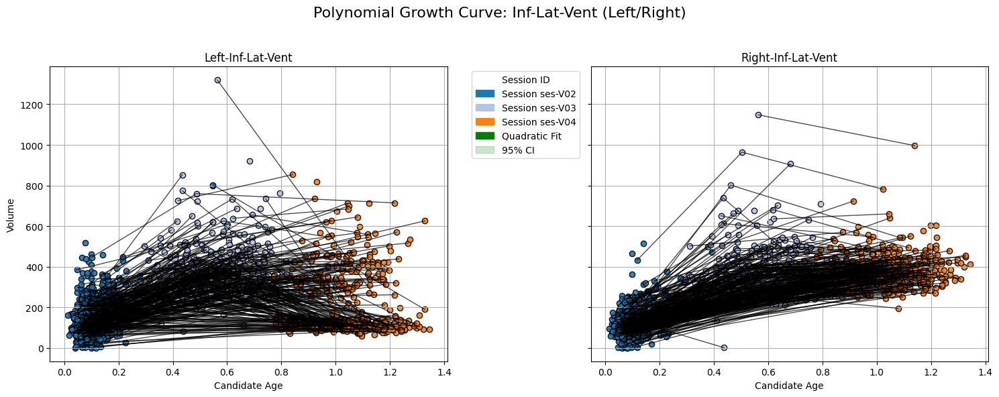

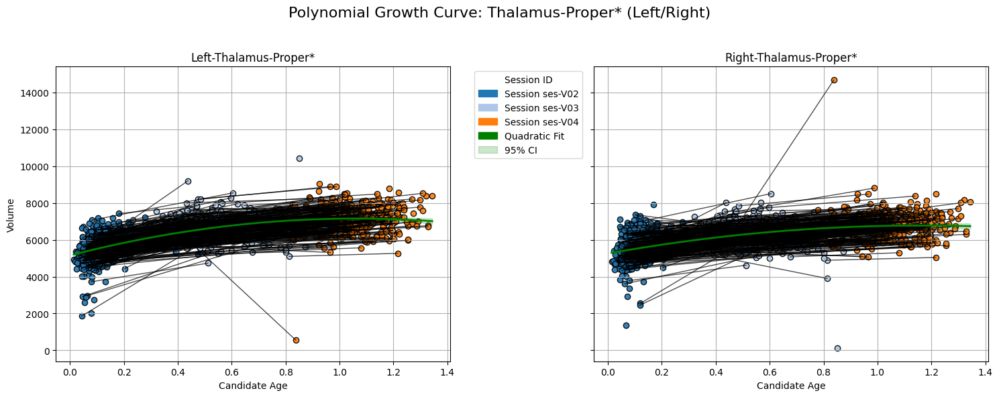

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

def plot_left_right_pairs(
    df,
    age_col,
    participant_col,
    session_col,
    prefix="img_bibsnet_space-T1w_desc-aseg_volumes_"
):
    # Step 1: Find unique structure names for pairing
    region_cols = [col for col in df.columns if col.startswith(prefix)]
    structure_names = [col.replace(prefix, '') for col in region_cols]

    # Build dictionary of pairs: {'Cerebral-Cortex': {'Left': col, 'Right': col}}
    pairs = {}
    for name, col in zip(structure_names, region_cols):
        if name.startswith('Left-'):
            base_name = name.replace('Left-', '')
            pairs.setdefault(base_name, {})['Left'] = col
        elif name.startswith('Right-'):
            base_name = name.replace('Right-', '')
            pairs.setdefault(base_name, {})['Right'] = col

    # Get session colors
    color_palette = plt.cm.tab20.colors  # Up to 20, use tab20 for more sessions
    session_ids = sorted(df[session_col].unique())
    session_colors = dict(zip(session_ids, color_palette[:len(session_ids)]))

    # Step 2: Plot for each pair
    for base_name, pair in pairs.items():
        fig, axes = plt.subplots(1, 2, figsize=(15, 6), sharey=True)
        sides = ['Left', 'Right']

        for i, side in enumerate(sides):
            if side in pair:
                region_col = pair[side]
                region_name = f"{side}-{base_name}"

                x = df[age_col].values
                y = df[region_col].values

                # Polynomial fit and CI
                coefs = np.polyfit(x, y, 2)
                x_curve = np.linspace(x.min(), x.max(), 200)
                y_poly = np.polyval(coefs, x_curve)
                X = np.vstack([x**2, x, np.ones_like(x)]).T
                X_pred = np.vstack([x_curve**2, x_curve, np.ones_like(x_curve)]).T
                y_fit = np.polyval(coefs, x)
                residuals = y - y_fit
                dof = len(x) - 3
                residual_var = (residuals**2).sum() / dof
                XtX_inv = np.linalg.inv(X.T @ X)
                y_var_pred = np.array([residual_var * (np.dot(X_pred[j], XtX_inv @ X_pred[j])) for j in range(len(x_curve))])
                y_std_pred = np.sqrt(y_var_pred)
                ci_upper = y_poly + 1.96 * y_std_pred
                ci_lower = y_poly - 1.96 * y_std_pred

                ax = axes[i]
                # Plot session colored points and connect by subject
                for pid, group in df.groupby(participant_col):
                    group_sorted = group.sort_values(age_col)
                    for sid in session_ids:
                        session_group = group_sorted[group_sorted[session_col] == sid]
                        if not session_group.empty:
                            ax.scatter(
                                session_group[age_col], session_group[region_col],
                                color=session_colors[sid], alpha=0.9, edgecolor='black', label=None
                            )
                    if len(group_sorted) > 1:
                        ax.plot(
                            group_sorted[age_col], group_sorted[region_col],
                            color='black', alpha=0.7, linewidth=1
                        )
                # Poly fit curve and CI
                ax.plot(x_curve, y_poly, color='green', linewidth=2, label='Quadratic Fit')
                ax.fill_between(x_curve, ci_lower, ci_upper, color='green', alpha=0.2, label='95% CI')
                ax.set_xlabel('Candidate Age')
                ax.set_title(region_name)

        # Custom legend (put only on first subplot)
        handles = [mpatches.Patch(color=session_colors[sid], label=f'Session {sid}') for sid in session_ids]
        handles += [
            mpatches.Patch(color='green', label='Quadratic Fit'),
            mpatches.Patch(color='green', alpha=0.2, label='95% CI')
        ]
        axes[0].legend(handles=handles, title='Session ID', bbox_to_anchor=(1.05, 1), loc='upper left')

        axes[0].set_ylabel('Volume')
        for ax in axes:
            ax.grid(True)
        plt.suptitle(f'Polynomial Growth Curve: {base_name} (Left/Right)', fontsize=16)
        plt.tight_layout(rect=[0, 0, 1, 0.95])
        # Optionally:
        # plt.savefig(f'growth_curve_{base_name}_left_right.png')
        plt.show()

# Usage
plot_left_right_pairs(
    df,
    age_col='img_bibsnet_space-T1w_desc-aseg_volumes_candidate_age',
    participant_col='participant_id',
    session_col='session_id',
    prefix='img_bibsnet_space-T1w_desc-aseg_volumes_'
)

### Output all charts within a PDF document

In [20]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.backends.backend_pdf import PdfPages

def plot_and_export_regions(
    df,
    age_col,
    participant_col,
    session_col,
    prefix="img_bibsnet_space-T1w_desc-aseg_volumes_",
    pdf_filename="all_growth_curves.pdf"
):
    # Identify region columns and structure base names
    region_cols = [col for col in df.columns if col.startswith(prefix)]
    structure_names = [col.replace(prefix, '') for col in region_cols]
    pairs = {}
    singletons = []

    # Find pairs and unpaired
    for name, col in zip(structure_names, region_cols):
        if name.startswith('Left-'):
            base = name.replace('Left-', '')
            pairs.setdefault(base, {})['Left'] = col
        elif name.startswith('Right-'):
            base = name.replace('Right-', '')
            pairs.setdefault(base, {})['Right'] = col
        else:
            singletons.append((name, col))

    # Split pairs into true pairs and leftover singles
    paired_structures = {k: v for k, v in pairs.items() if len(v) == 2}
    leftover = [(f"Left-{k}", v['Left']) for k, v in pairs.items() if 'Left' in v and 'Right' not in v]
    leftover += [(f"Right-{k}", v['Right']) for k, v in pairs.items() if 'Right' in v and 'Left' not in v]
    all_singletons = singletons + leftover

    # Session colors
    color_palette = plt.cm.tab20.colors
    session_ids = sorted(df[session_col].unique())
    session_colors = dict(zip(session_ids, color_palette[:len(session_ids)]))

    # PDF output
    with PdfPages(pdf_filename) as pdf:
        # -- Plot left-right pairs --
        for base_name, pair in paired_structures.items():
            fig, axes = plt.subplots(1, 2, figsize=(15, 7), sharey=True)
            sides = ['Left', 'Right']
            for i, side in enumerate(sides):
                region_col = pair[side]
                region_name = f"{side}-{base_name}"
                x = df[age_col].values
                y = df[region_col].values
                # Polynomial fit and CI
                coefs = np.polyfit(x, y, 2)
                x_curve = np.linspace(x.min(), x.max(), 200)
                y_poly = np.polyval(coefs, x_curve)
                X = np.vstack([x**2, x, np.ones_like(x)]).T
                X_pred = np.vstack([x_curve**2, x_curve, np.ones_like(x_curve)]).T
                y_fit = np.polyval(coefs, x)
                residuals = y - y_fit
                dof = len(x) - 3
                residual_var = (residuals**2).sum() / dof
                XtX_inv = np.linalg.inv(X.T @ X)
                y_var_pred = np.array([residual_var * (np.dot(X_pred[j], XtX_inv @ X_pred[j])) for j in range(len(x_curve))])
                y_std_pred = np.sqrt(y_var_pred)
                ci_upper = y_poly + 1.96 * y_std_pred
                ci_lower = y_poly - 1.96 * y_std_pred
                ax = axes[i]
                # Plot session colored points and lines
                for pid, group in df.groupby(participant_col):
                    group_sorted = group.sort_values(age_col)
                    for sid in session_ids:
                        session_group = group_sorted[group_sorted[session_col] == sid]
                        if not session_group.empty:
                            ax.scatter(
                                session_group[age_col], session_group[region_col],
                                color=session_colors[sid], alpha=0.9, edgecolor='black', label=None
                            )
                    if len(group_sorted) > 1:
                        ax.plot(
                            group_sorted[age_col], group_sorted[region_col],
                            color='black', alpha=0.7, linewidth=1
                        )
                # Poly fit curve and CI
                ax.plot(x_curve, y_poly, color='green', linewidth=2, label='Quadratic Fit')
                ax.fill_between(x_curve, ci_lower, ci_upper, color='green', alpha=0.2, label='95% CI')
                ax.set_xlabel('Age (years)')
                ax.set_title(region_name)
            
            handles = [mpatches.Patch(color=session_colors[sid], label=f'Session {sid}') for sid in session_ids]
            handles += [
                mpatches.Patch(color='green', label='Quadratic Fit'),
                mpatches.Patch(color='green', alpha=0.2, label='95% CI')
            ]
            axes[0].legend(handles=handles, title='Session ID', bbox_to_anchor=(1.05, 1), loc='upper left')
            axes[0].set_ylabel('Volume (mm³)')
            for ax in axes:
                ax.grid(True)
            plt.suptitle(f'Polynomial Growth Curve: {base_name} (Left/Right)', fontsize=16)
            plt.tight_layout(rect=[0, 0, 1, 0.95])
            pdf.savefig(fig)
            plt.close(fig)

        # -- Plot unpaired structures --
        for region_name, region_col in all_singletons:
            fig, ax = plt.subplots(figsize=(12, 7))
            x = df[age_col].values
            y = df[region_col].values
            # Polynomial fit and CI
            coefs = np.polyfit(x, y, 2)
            x_curve = np.linspace(x.min(), x.max(), 200)
            y_poly = np.polyval(coefs, x_curve)
            X = np.vstack([x**2, x, np.ones_like(x)]).T
            X_pred = np.vstack([x_curve**2, x_curve, np.ones_like(x_curve)]).T
            y_fit = np.polyval(coefs, x)
            residuals = y - y_fit
            dof = len(x) - 3
            residual_var = (residuals**2).sum() / dof
            XtX_inv = np.linalg.inv(X.T @ X)
            y_var_pred = np.array([residual_var * (np.dot(X_pred[j], XtX_inv @ X_pred[j])) for j in range(len(x_curve))])
            y_std_pred = np.sqrt(y_var_pred)
            ci_upper = y_poly + 1.96 * y_std_pred
            ci_lower = y_poly - 1.96 * y_std_pred
            # Plot session colored points and lines
            for pid, group in df.groupby(participant_col):
                group_sorted = group.sort_values(age_col)
                for sid in session_ids:
                    session_group = group_sorted[group_sorted[session_col] == sid]
                    if not session_group.empty:
                        ax.scatter(
                            session_group[age_col], session_group[region_col],
                            color=session_colors[sid], alpha=0.9, edgecolor='black', label=None
                        )
                if len(group_sorted) > 1:
                    ax.plot(
                        group_sorted[age_col], group_sorted[region_col],
                        color='black', alpha=0.7, linewidth=1
                    )
            ax.plot(x_curve, y_poly, color='green', linewidth=2, label='Quadratic Fit')
            ax.fill_between(x_curve, ci_lower, ci_upper, color='green', alpha=0.2, label='95% CI')
            ax.set_xlabel('Age (years)')
            ax.set_ylabel('Volume (mm³)')
            ax.set_title(region_name)
            handles = [mpatches.Patch(color=session_colors[sid], label=f'Session {sid}') for sid in session_ids]
            handles += [
                mpatches.Patch(color='green', label='Quadratic Fit'),
                mpatches.Patch(color='green', alpha=0.2, label='95% CI')
            ]
            ax.legend(handles=handles, title='Session ID', bbox_to_anchor=(1.05, 1), loc='upper left')
            ax.grid(True)
            plt.suptitle(f'Polynomial Growth Curve: {region_name}', fontsize=16)
            plt.tight_layout(rect=[0, 0, 1, 0.95])
            pdf.savefig(fig)
            plt.close(fig)

# Usage
plot_and_export_regions(
    df, 
    age_col='img_bibsnet_space-T1w_desc-aseg_volumes_candidate_age', 
    participant_col='participant_id', 
    session_col='session_id', 
    prefix='img_bibsnet_space-T1w_desc-aseg_volumes_',
    pdf_filename='all_growth_curves.pdf'
)

## Visualize Model Weights on Brain

Brain-based visualizations are a key component for inspecting and communicating neuroimaging findings and results. The final code block contains instructions to produce statistical maps on NIFTI (`nii.gz`) volumes. While that block is quite complex, there are several easy ways for researchers to customize the code to answer their question their way. The template data can be changed to other templates by changing the `src` variable. You can specify where you want your outputs located by changning the `out_dir` variable. Changing the `age col`, `img_bibsnet_space-T1w_desc-aseg_volumes_candidate_age` changes what is plotted on the X axis, while changing the `prefix` , `img_bibsnet_space-T1w_desc-aseg_volumes_` will enable you to choose whatever tabulated data you want to use. Please keep in mind that the corresponding outputs produced in `outputs` may require corresponding changes to the `src` templates as well.



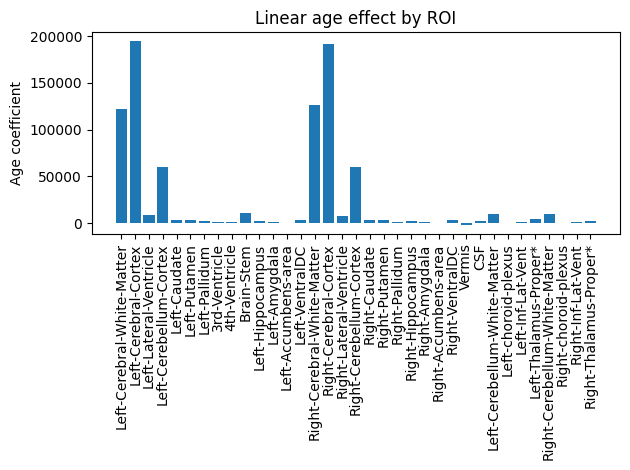

In [23]:
import pandas as pd
import numpy as np
import nibabel as nib
import matplotlib.pyplot as plt
from numpy.polynomial.polynomial import Polynomial

# PREPARE DATA
# Define source and output data file paths provided in repo
src = "data/src"
out_dir = "data/outputs"

# Define age column and ROI columns to loop through from HBCD data (exclude age columns and Unknown ROI)
# NOTE! Can use T1w or T2w results here
age_col='img_bibsnet_space-T1w_desc-aseg_volumes_candidate_age'
prefix='img_bibsnet_space-T1w_desc-aseg_volumes_'
roi_cols = [col for col in df.columns if col.startswith(prefix) and 'age' not in col and 'Unknown' not in col]

# POLYNOMIAL FIT
# Compute model weights for each ROI using a polynomial fit of age to volume, and store in a new dataframe
roi_weights = []
    
for roi in roi_cols:
    roi_name = roi.replace(prefix, '') # strip prefix for ROIs just for plot
    
    # Flatten into one array (note: ignores repeated participants). Also drop NaNs to avoid issues with polynomial fit
    valid = df[[age_col, roi]].dropna()
    x = valid[age_col].to_numpy().ravel()
    y = valid[roi].to_numpy().ravel()

    # Polynomial fit
    coefs = Polynomial.fit(x, y, deg=2).convert().coef

    roi_weights.append({
        "roi": roi_name,
        "intercept": coefs[0],
        "age_linear": coefs[1],
        "age_quadratic": coefs[2]
    })

# View results as bar plot for linear weights
weights_df = pd.DataFrame(roi_weights)
weights_df.head

# Note! You can replace age_linear here with age_quadratic depending on which model weights are of interest
plt.bar(weights_df['roi'], weights_df['age_linear'])
plt.xticks(rotation=90)
plt.ylabel("Age coefficient") 
plt.title("Linear age effect by ROI") # or 'Quadratic age effect by ROI'
plt.tight_layout()
plt.show()
plt.savefig("data/outputs/linear_age_effects_by_roi.png")

# REPLACE ROI LABELS IN PROVIDED TEMPLATE BRAIN SEGMENTATION FILE WITH MODEL WEIGHT VALUES
# Read in FreeSurfer lookup table to get FreeSurfer label IDs for each ROI (note: this file only includes the ROIs defined for HBCD data) and merge with weights DF on the roi column to integrate model weights
lut_df = pd.read_csv(f"{src}/FreeSurfer-LUT-short.csv")
roi_df = pd.merge(lut_df, weights_df, on="roi", how="inner")
roi_df.head

# Convert FreeSurfer ROI labels to model weight values (output as file roi_weights_volume.nii.gz)
template_aseg = f'{src}/sub-380056/ses-7mo/anat/sub-380056_ses-7mo_space-INFANTMNIacpc_desc-aseg_dseg.nii.gz'
out_vol = f'{out_dir}/roi_weights_volume.nii.gz' # Adjust this filename as wanted (e.g. to specify linear vs quadratic model weights mapped)

# Load aseg
aseg_img = nib.load(template_aseg)
aseg_data = aseg_img.get_fdata().astype(int)

# Create output array (float for weights)
weights_data = np.zeros_like(aseg_data, dtype=float)

# Map labels > weights and apply mapping
# Note! You can replace age_linear here with age_quadratic depending on which model weights are of interest
label_to_weight = dict(zip(roi_df["label"], roi_df["age_linear"]))
for label, weight in label_to_weight.items():
    weights_data[aseg_data == label] = weight

# Save new NIfTI
out_img = nib.Nifti1Image(weights_data, affine=aseg_img.affine, header=aseg_img.header)
nib.save(out_img, out_vol)